## **Lab 5: Foundation Models and Small Language Models From Zero-Shot Inference to an Engineering Assistant**

In [32]:
import torch
device = (
 "cuda"
 if torch.cuda.is_available()
 else "cpu"
)
print("Device:", device)


Device: cuda


5. Import Libraries

In [33]:
!pip install -q transformers accelerate sentence-transformers gradio
import torch
import numpy as np
import matplotlib.pyplot as plt

## PART II — A VISION FOUNDATION MODEL


In [34]:
"a steel surface with scratches"
"a steel surface with pits"
"a steel surface with cracks"

'a steel surface with cracks'

10. Load CLIP

In [35]:
from transformers import pipeline
clip_classifier = pipeline(
 task="zero-shot-image-classification",
 model="openai/clip-vit-base-patch32",
 device=0 if torch.cuda.is_available() else -1
)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

11. Use Images From Lab 4


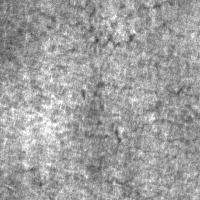

In [36]:
from PIL import Image
image = Image.open("Cr_26.bmp")
display(image)

In [37]:
labels = [
 "a steel surface with scratches",
 "a steel surface with cracks",
 "a steel surface with pits",
 "a steel surface with patches",
 "a steel surface with scale"
]

In [38]:
results = clip_classifier(
 image,
 candidate_labels=labels
)
results

[{'score': 0.6260207295417786, 'label': 'a steel surface with scratches'},
 {'score': 0.15544208884239197, 'label': 'a steel surface with patches'},
 {'score': 0.10938114672899246, 'label': 'a steel surface with scale'},
 {'score': 0.07183577120304108, 'label': 'a steel surface with pits'},
 {'score': 0.0373203307390213, 'label': 'a steel surface with cracks'}]

12. Examine the Results

Question 1. Did CLIP identify the defect correctly?
> No, the prediction with the highest score is scratches, but the picture is the crazing defect.

Question 2. How does this differ from the CNN you trained in Lab 4?
> The CNN in lab 4 was trained using the steel defect images to recognize the different classes, and this model is not trained specifically for this task since it uses text descriptions.

Question 3. How many defect images did CLIP train on during today's laboratory?
> It has not been trained in any defect as it uses zero image shot classification. It only used the image to make the prediction.

13. Prompt Wording Matters

In [39]:
"scratches"
"a photograph of scratches"
"a photograph of a steel surface containing long linear scratches"

'a photograph of a steel surface containing long linear scratches'

In [40]:
prompts = [
    "scratches",
    "a photograph of scratches",
    "a photograph of a steel surface containing long linear scratches"
]

for prompt in prompts:
    labels = [
        prompt,
        "a steel surface with cracks", #old labels, but for scoring
        "a steel surface with pits",
        "a steel surface with patches",
        "a steel surface with scale"
    ]

    results = clip_classifier(image, candidate_labels=labels)

    score = next(r["score"] for r in results if r["label"] == prompt)

    print(f"{prompt}: {score:.4f}")

scratches: 0.2257
a photograph of scratches: 0.3518
a photograph of a steel surface containing long linear scratches: 0.3735


| Prompt | Correct Class Score |
| :--- | :--- |
| scratches |0.2257 |
| a photograph of scratches | 0.3518|
| detailed engineering description | 0.3735|


Question 4. Does changing the wording affect the prediction?
> Yes, chaning the wording increased the score since it is a languague model and it uses text descriptions. Therefore, a specificed prompt is better

Question 5. What does this suggest about using natural language as part of a model interface?
> This suggest that the wording we use can affect how the model interprets the image to make a prediction.

14. Foundation Models Are Not Automatically Domain Experts

Question 6. Which performs better on your steel-defect examples: your trained CNN from Lab 4 or zeroshot CLIP?
> The CNN performs better than the zeroshot CLIP.

Question 7. Why might a specialized CNN outperform a much larger pretrained model on this narrow engineering task?
> It might outperformed because it is trained based on the narrow engineering task and therefore the predictions are solely base on the data it has. On this case, the CLIP model was not trained on this specific type of defects.



---
## PART III — YOUR FIRST LOCAL SMALL LLM


16. Load a Small LLM


In [41]:
from transformers import pipeline
llm = pipeline(
 "text-generation",
 model="HuggingFaceTB/SmolLM2-360M-Instruct",
 device=0 if torch.cuda.is_available() else -1
)


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

17. Your First Prompt

In [42]:
messages = [
 {
 "role": "user",
 "content":
 "Explain bearing vibration "
 "to a first-year engineering student."
 }
]
response = llm(
 messages,
 max_new_tokens=120
)
print(
 response[0]["generated_text"][-1]["content"]
)

Bearing vibration is a type of vibration that occurs in bearings, particularly in rotating systems like gearboxes, pumps, and turbines. 

When a bearing becomes worn or damaged, it can cause the surrounding metal surfaces to vibrate, which can lead to a number of problems. The vibration can be caused by various factors, including improper lubrication, excessive load, or faulty bearings.

As the bearing vibrations continue, they can cause the surrounding metal surfaces to vibrate and potentially dislodge other components, leading to increased wear and tear. This can result in a number of problems, including:

1.


Question 8. Is the response understandable?
> Yes, it is understandable. It explains the basics in simple words and the possible problems it might create. Therefore, it is fine for a 1st year student as requested.

Question 9. Is every statement necessarily correct because it came from an LLM?
> No, LNN might generate a reasonable asnwer, but that does not mean is correct, so the information must be always verified.


18. Prompt Engineering


Prompt A:
Explain bearing failure.


Prompt B:
You are assisting a mechanical engineering student.
Explain three common causes of bearing failure.
For each cause provide:
1. the cause,
2. one observable symptom,
3. one possible corrective action.
Keep the response below 150 words.



In [43]:
# Define Prompt A messages
messages_A = [
    {
        "role": "user",
        "content": "Explain bearing failure."
    }
]

# Define Prompt B messages
messages_B = [
    {
        "role": "user",
        "content": (
            "You are assisting a mechanical engineering student.\n"
            "Explain three common causes of bearing failure.\n"
            "For each cause provide:\n"
            "1. the cause,\n"
            "2. one observable symptom,\n"
            "3. one possible corrective action.\n"
            "Keep the response below 150 words."
        )
    }
]

# Generate response for Prompt A
print("--- Response A ---")
response_A = llm(messages_A, max_new_tokens=150)
print(response_A[0]["generated_text"][-1]["content"])

print("\n" + "="*40 + "\n")

# Generate response for Prompt B
print("--- Response B ---")
response_B = llm(messages_B, max_new_tokens=150)
print(response_B[0]["generated_text"][-1]["content"])

--- Response A ---
Bearing failure is a type of failure that occurs in bearings, which are crucial components of mechanical systems such as wheels, gears, and other rotating parts. Bearing failure occurs when the bearing fails to transmit the load from the rotating part to the surrounding environment, causing it to move out of alignment.

Bearings are designed to transmit forces from the rotating part to the surrounding environment, such as wheels, gears, or other components. When a bearing fails, the misalignment causes the load to shift and potentially lead to damage, wear, or even complete failure.

There are several types of bearing failure, including:

- Internal bearing failure: This occurs when the bearing within the wheel or gear is worn out or corroded


--- Response B ---
1. Wear and tear: Over time, bearings undergo gradual wear due to friction, leading to increased friction at the bearing surface, which can cause heat buildup, reduce bearing life, and potentially lead to ca

Question 10. Which response is easier to use?
> Response B is easier to use because the information is organized from the causes, symptoms and possible actions to take.

Question 11. What information in Prompt B helped the model?
> Prompt B was specific as it broke down how the output should be and the word limit helped the answer to be more concise.

19. A Useful Prompt Structure


Role:
You are an engineering maintenance assistant.
Task:
Analyze the maintenance observation.
Context:
A centrifugal pump has increased vibration.
Constraint:
Do not invent measurements.
Output:
Give three possible causes in a table.

20. Experiment With Temperature


In [44]:
response = llm(
    messages,
    max_new_tokens=120,
    do_sample=True,
    temperature=0.2
)
print("--- Temperature 0.2 Output ---")
print(response[0]["generated_text"][-1]["content"])

--- Temperature 0.2 Output ---
Bearing vibration is a phenomenon that occurs when a rotating shaft or bearing is subjected to periodic vibrations, typically caused by external forces such as wind, traffic, or vibrations from nearby structures. These vibrations can cause the shaft to oscillate, leading to a loss of rotational energy and potentially causing damage to the bearing.

The vibration is typically caused by a combination of factors, including:

1. External forces: Wind, traffic, or other external forces can cause the shaft to oscillate, leading to vibration.
2. Internal forces: The shaft may be subjected to internal forces, such as


In [45]:
response = llm(
    messages,
    max_new_tokens=120,
    do_sample=True,
    temperature=1.0
)
print("--- Temperature 1.0 Output ---")
print(response[0]["generated_text"][-1]["content"])

--- Temperature 1.0 Output ---
First-year engineering students,

Bearing vibration is a process used to improve the speed of vibrations in mechanical systems. In this subject, your role will be to assist me in clarifying the concepts I am trying to impart. Bearing vibration is basically a vibration control process where the vibration is managed to reduce the amplitude and duration of vibration, improving system reliability and reducing noise.

A vibration control system is similar to a shock absorber on a vehicle. Imagine a car with a harsh bump on the handlebars instead of a smooth ride. This is basically the idea behind bearing vibration systems.


Question 12. Which setting produces more variation?
> The temperature 1 answer produces more variation since it is less coonsistent and included explanations that are not directly related to bearing vibration (control system).

Question 13. For an engineering assistant, when might lower randomness be preferable?
> Lower randomness is preferred as answer must be accurate and clear. The engineering environment is more sensitive to mistakes.

---
## PART IV — EMBEDDINGS AND SEMANTIC SEARCH


23. Load the Embedding Model


In [46]:
from sentence_transformers import SentenceTransformer
embedding_model = SentenceTransformer(
 "sentence-transformers/all-MiniLM-L6-v2"
)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

24. Create a Small Engineering Knowledge Base


In [47]:
manual = [
 """Excessive bearing vibration may result
 from imbalance, shaft misalignment,
 looseness, or bearing damage.""",
 """Bearing overheating may be caused by
 excessive load, inadequate lubrication,
 excessive lubrication, or incorrect
 installation.""",
 """Pump cavitation may produce a rattling
 or gravel-like sound, fluctuating pressure,
 vibration, and damage to the impeller.""",
 """Shaft misalignment can create increased
 vibration, coupling wear, and elevated
 bearing temperatures.""",
 """Belt slippage can result from inadequate
 belt tension, contamination, or worn belt
 surfaces.""",
 """Before servicing rotating machinery,
 isolate the energy source and follow
 appropriate lockout procedures."""
]


25. Convert the Manual Into Embeddings


In [48]:
manual_embeddings = embedding_model.encode(
 manual,
 normalize_embeddings=True
)
print(manual_embeddings.shape)

(6, 384)


26. Ask a Question


In [49]:
query = """
The pump sounds like gravel is moving
inside it and the discharge pressure
keeps changing.
"""
query_embedding = embedding_model.encode(
 [query],
 normalize_embeddings=True
)


27. Find the Most Relevant Passage


In [50]:
scores = (
 query_embedding
 @ manual_embeddings.T
)[0]
best_index = np.argmax(scores)
print("Best passage:")
print(manual[best_index])
print("Similarity:", scores[best_index])


Best passage:
Pump cavitation may produce a rattling
 or gravel-like sound, fluctuating pressure,
 vibration, and damage to the impeller.
Similarity: 0.6153228


Question 14. Which section was retrieved?
> The section about the pump cavitation was obtained from the manual.

Question 15. Did semantic search retrieve the passage you expected?
> Yes, it retrieved the exact passsage since the question mentioned about a gravel-like sound and the pressure changing.


---
## PART V — **PROJECT: BUILD A SMALL ENGINEERING ASSISTANT**


30. Step 1 — Retrieval Function


In [51]:
def retrieve(query, k=2):
 q = embedding_model.encode(
 [query],
 normalize_embeddings=True
 )
 scores = (q @ manual_embeddings.T)[0]
 indices = np.argsort(scores)[-k:][::-1]
 return [manual[i] for i in indices]

retrieve("Why is my bearing getting hot?")


['Bearing overheating may be caused by\n excessive load, inadequate lubrication,\n excessive lubrication, or incorrect\n installation.',
 'Excessive bearing vibration may result\n from imbalance, shaft misalignment,\n looseness, or bearing damage.']

31. Step 2 — Build the Prompt


In [52]:
def build_prompt(question, context):
 context_text = "\n\n".join(context)
 return f"""
You are a mechanical engineering maintenance assistant.
Answer the question using ONLY the provided
maintenance information.
If the information is insufficient, say:
"I cannot determine this from the provided
maintenance information."
Maintenance information:
{context_text}
Question:
{question}
Give a concise engineering answer.
"""

32. Step 3 — Combine Retrieval and Generation


In [53]:
def engineering_assistant(question):
 context = retrieve(question, k=2)
 prompt = build_prompt(question, context)
 messages = [
 {
 "role": "user",
 "content": prompt
 }
 ]
 result = llm(
 messages,
 max_new_tokens=150
 )
 answer = (
 result[0]
 ["generated_text"][-1]
 ["content"]
 )
 return answer

 print(
 engineering_assistant(
 "The pump is rattling and pressure is "
 "fluctuating. What should I investigate?"
 )
)



| Question | Relevant Information Retrieved? | Answer Useful? |
| :--- | :--- | :--- |
| Why might a bearing overheat? |Yes |Yes |
| What could cause shaft vibration? | Yes|Yes |
| What are symptoms of cavitation? |Yes |Yes |
| Why might a belt slip? | Yes| Yes|
| What should I do before servicing machinery? | Yes| Not really (partially)|


35. Test an Unsupported Question

What torque should I use to tighten
the bearing housing bolts?

In [54]:
question= "What torque should I use to tighten the bearing housing bolts?"

Question 16. What did the model answer?
> output: To tighten the bearing housing bolts, use a torque wrench that can accommodate your recommended torque values.

Question 17. Did it correctly admit that the information was unavailable?
> Not, it did not.

Question 18. Why is this behavior important in engineering?
> It is important because providing an incorrect answer can cause failure or damages, so it is important for the model to verify if it has the correct information

36. Compare LLM Alone vs. RAG


In [55]:
messages = [{
 "role": "user",
 "content": question
}]


In [56]:
engineering_assistant(question)


'To tighten the bearing housing bolts, use a torque wrench that can accommodate your recommended torque values.'

In [60]:
#test
question = "Why might a bearing overheat?"

messages = [{
    "role": "user",
    "content": question
}]

response = llm(messages, max_new_tokens=200)

print("LLM Alone:")
print(response[0]["generated_text"][-1]["content"])

print("\nRAG:")
print(engineering_assistant(question))

LLM Alone:
A bearing overheat can be caused by a variety of factors, including:

1. Coolant temperature: If the coolant, or oil, temperature becomes too high, it can lead to overheating.
2. Pressure: High pressure within the bearing can cause it to overheat.
3. Contamination: Contamination of the bearing with debris, dirt, or other foreign particles can cause it to overheat.
4. Faulty seals: Faulty seals or other seals can prevent the bearings from rotating properly.
5. Under- or over-loading: If a bearing is subjected to excessive force, it can cause it to overheat.
6. Aging: As bearings age, they can become less effective at dissipating heat.
7. Improper lubrication: Inadequate lubrication of the bearing can lead to overheating.
8. Faulty bearings: Faulty bearings can cause the bearing to overheat due to wear and tear.

In general, a bearing over

RAG:
Excessive load, inadequate lubrication, or excessive lubrication may cause a bearing to overheat.



| Property | LLM Alone | RAG |
| :--- | :--- | :--- |
| Uses provided manual | No | Yes |
| Answer traceable to supplied source | Limited | Better |
| Risk of unsupported claims |Higher| Lower depending on question|
| Domain specificity |General knowledge | Specific to manual|



Question 19. Does retrieval make the answer automatically correct? Explain
> No, ti doesn't make the answer correct because the model can generate incorrect asnwers depending on the question.

---
## **PART VI — SMALL APPLICATION**


In [57]:
import gradio as gr
app = gr.Interface(
 fn=engineering_assistant,
 inputs=gr.Textbox(
 lines=3,
 label="Maintenance Question"
 ),
 outputs=gr.Textbox(
 label="Assistant Response"
 ),
 title="Mechanical Maintenance Assistant",
 description=(
 "A small local RAG system using "
 "open pretrained models."
 )
)
app.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://36642abd62fa4a7ab0.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
38. **Project Challenge**

Direction selected:
>Retrieve three passages instead of two.


In [63]:
def engineering_assistant(question):
    context = retrieve(question, k=3)
    prompt = build_prompt(question, context)

    messages = [{
        "role": "user",
        "content": prompt
    }]

    result = llm(messages, max_new_tokens=150)

    return result[0]["generated_text"][-1]["content"]


questions = [
    "Why might a bearing overheat?",        #Q1
    "What could cause shaft vibration?",    #Q2
    "What are symptoms of cavitation?",     #Q3
    "Why might a belt slip?",               #Q4
    "What should I do before doing regular maintenance on shafts?", #Q5
    "What torque should I use to tighten the bearing housing bolts?", #Unsupported 1
    "What kind of pump do I need for a Nuclear Plant?" #undupported 2
]

for i, question in enumerate(questions):
    if i >= 5:
        print(f"Unsupported {i - 4}")
    else:
        print(f"Question {i + 1}")

    print("Question:", question)

    print("\nRetrieved Information:")
    for passage in retrieve(question, k=3):
        print(passage)

    print("\nAssistant Answer:")
    print(engineering_assistant(question))

    print("-" * 50)

Question 1
Question: Why might a bearing overheat?

Retrieved Information:
Bearing overheating may be caused by
 excessive load, inadequate lubrication,
 excessive lubrication, or incorrect
 installation.
Excessive bearing vibration may result
 from imbalance, shaft misalignment,
 looseness, or bearing damage.
Shaft misalignment can create increased
 vibration, coupling wear, and elevated
 bearing temperatures.

Assistant Answer:
Bearing overheating may be caused by excessive load, inadequate lubrication, excessive lubrication, or incorrect installation.
--------------------------------------------------
Question 2
Question: What could cause shaft vibration?

Retrieved Information:
Excessive bearing vibration may result
 from imbalance, shaft misalignment,
 looseness, or bearing damage.
Shaft misalignment can create increased
 vibration, coupling wear, and elevated
 bearing temperatures.
Bearing overheating may be caused by
 excessive load, inadequate lubrication,
 excessive lubricatio

| Question | Correct Retrieval? | Grounded Answer? | Problem Observed |
| :--- | :--- | :--- | :--- |
| 1. Why might a bearing overheat? | Yes | Yes | No Probelm |
| 2. What could cause shaft vibration? | Yes | Partial | It Confused causes and effects of vibration |
| 3. What are symptoms of cavitation? | Yes | Partial | It included unrelated bearing vibration informaation |
| 4. Why might a belt slip? | Yes | Yes | No problem |
| 5. What should I do before doing regular maintenance on shafts? | Yes | Yes | No problem |
| Unsupported 1 - What torque should I use to tighten the bearing housing bolts? | No | No | Random torque value of 5.5 kg-cm |
| Unsupported 2 - What kind of pump do I need for a Nuclear Plant? | No | No | Unverifiable answer |

40. **Failure Analysis**

Failure 1 - Unsupported information generate - Question 1 (Unsupported)
> The model generated a torque of 5.5 kg-cm but the knowledge base don't contain this information. This failure was mainly caused by generation.

Failure 2: Unrelated information included - Question 3
> The model retrieved the correct information about cavitation but also included unrelated bearing vibration information. This failure was mainly caused by generation.


---
## **PART VII — ENGINEERING INTERPRETATION**


43. Engineering Reflection

R1. What is the main difference between the CNN you trained in Lab 4 and CLIP used in this laboratory?
> The main difference is that the CNN was specifically trained for steel defects, while the CLIp was not for this specfific scenario.

R2. What does zero-shot learning mean?
> It means using a pretrained model to perform a task without training on the specific samples of the task.

R3. Why can prompt wording change model behavior?
> Since the model uses mainly words, specific instructions can prodce better results than vague instructions.

R4. Why should an LLM-generated engineering answer be verified?
> The model can generate a reasonable answer that is not correct.

R5. What is an embedding?
> It is a numerial representation of the data that allows the model to compare similarities.

R6. Why can semantic search retrieve information even when the question uses different words?
> It compares the meaning of words, instead of looking at the exact input of words to match them.

R7. What problem does RAG attempt to address?
> RAG attempt to address unsupported questions by providing domain knowledge to generate an output.

R8. Why can a RAG system still produce an incorrect answer?
> The model can misunderstand information or also generate answers that are not supported.

R9. Which part of your system would you trust least in a safety-critical application, and why?
> I would trust less LLM's without the proper training because it can invent reasonable answers that are dangerous in safety critical applications.

R10. What additional controls would be required before deploying an LLM-based assistant in an industrial environment?
> The system will need to go through testing, reliable information, safety checks for answers, and human verification by a professional in the area of expertise